# ⌨️ Predictive Keyboard: next-word suggestion with LSTM / Transformer language models

This notebook builds a **smartphone-style predictive keyboard**. Given a sentence prefix such as
`"the president of the"`, it suggests the **next 1–3 words**, and it also handles a *partially typed* word
(`"the presid"` → `president`).

**What you will build**

| Stage | What happens |
|---|---|
| 1. Data | WikiText-2 → cleaning → word-level tokenizer → 10k vocabulary |
| 2. Model | A word-level **LSTM** language model *or* a small causal **Transformer** (one switch) |
| 3. Training | Cross-entropy next-token prediction, AdamW + OneCycle LR, early stopping |
| 4. Evaluation | Perplexity and **top-1 / top-3 / top-5 next-word accuracy** |
| 5. Keyboard engine | Top-k next words, partial-word autocomplete, beam-search phrase completion, confidence-based 1–3 word suggestions |
| 6. Demo | Interactive text box with 3 suggestion buttons (ipywidgets) |

> **Tip:** Training is fast on a GPU (about 20–40 s/epoch for the LSTM on a T4) and slow on a CPU. Google Colab's free GPU works well.

In [1]:
#pip install -q torch datasets ipywidgets matplotlib

In [2]:
import re, math, time, random, collections
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available()
                      else "mps" if getattr(torch.backends, "mps", None) and torch.backends.mps.is_available()
                      else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.15.0+cpu | device: cpu


## 1. Configuration

Change `MODEL_TYPE` to `"transformer"` to switch architectures. Everything downstream (training, evaluation, keyboard) works for both.

In [3]:
CFG = dict(
    MODEL_TYPE="lstm",        # "lstm" or "transformer"
    VOCAB_SIZE=10_000,        # most frequent words kept; the rest -> <unk>
    SEQ_LEN=32,               # context window (words) seen by the model
    BATCH_SIZE=128,
    EPOCHS=5,
    WEIGHT_DECAY=0.01,
    CLIP=1.0,
    CORPUS_PATH=None,         # optional: path to your own .txt file (one paragraph/sentence per line)
    CKPT_DIR="checkpoints",
    LSTM=dict(emb=400, hidden=400, layers=2, dropout=0.4, lr=2e-3),
    TRANSFORMER=dict(d_model=256, heads=8, layers=4, d_ff=1024, dropout=0.2, lr=1e-3),
)

## 2. Data: loading, cleaning, tokenizing

We use **WikiText-2** (≈2M training words). The tokenizer lowercases, keeps words/apostrophes/basic punctuation, maps digits to `<num>`,
and appends `<eos>` at the end of every line so the model learns how text *starts*, which matters for a keyboard, where the first word of a sentence is a common prediction request.

If you have your own text (chat logs, emails, …), set `CORPUS_PATH` above to personalize the keyboard.

In [4]:
SPECIALS = ["<pad>", "<unk>", "<eos>", "<num>"]
PAD, UNK, EOS, NUM = range(4)

TOKEN_RE = re.compile(r"[^\W\d_]+(?:'[^\W\d_]+)?|\d+|[.,!?;:]")
WORD_RE  = re.compile(r"^[^\W\d_]+(?:'[^\W\d_]+)?$")     # a "real" word (no punctuation / specials)

def tokenize_text(text):
    """Raw text -> list of tokens (no <eos>)."""
    text = text.lower()
    text = re.sub(r"(\d) @[.,]@ (\d)", r"\1\2", text)    # WikiText number artifacts "1 @,@ 000"
    text = re.sub(r"\s+'(?=\w)", "'", text)               # "didn 't" -> "didn't"
    text = text.replace(" n't", "n't")
    toks = TOKEN_RE.findall(text)
    return ["<num>" if t.isdigit() else t for t in toks]

def tokenize_line(line):
    line = line.strip()
    if not line or line.startswith("="):                  # skip blanks and wiki headings
        return []
    return tokenize_text(line) + ["<eos>"]

FALLBACK_TEXT = """
i would like to book a table for two people tonight .
the weather is going to be nice this weekend , so let's go to the park .
can you send me the report by the end of the day ?
thanks for your help , i really appreciate it .
what time does the meeting start tomorrow morning ?
i will be there in about ten minutes , see you soon .
the new phone has a great camera and a long battery life .
let me know if you have any questions about the project .
""".strip().splitlines()

def load_raw_lines():
    if CFG["CORPUS_PATH"]:
        lines = Path(CFG["CORPUS_PATH"]).read_text(encoding="utf-8").splitlines()
        n = len(lines); a, b = int(0.8 * n), int(0.9 * n)
        return lines[:a], lines[a:b], lines[b:]
    try:
        from datasets import load_dataset
        ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")
        return ds["train"]["text"], ds["validation"]["text"], ds["test"]["text"]
    except Exception as e:
        print("⚠️  Could not download WikiText-2 (%r).\n"
              "    Falling back to a tiny toy corpus (smoke-test only; set CORPUS_PATH for real data)." % (e,))
        lines = FALLBACK_TEXT * 60
        n = len(lines); a, b = int(0.8 * n), int(0.9 * n)
        return lines[:a], lines[a:b], lines[b:]

raw_train, raw_val, raw_test = load_raw_lines()

def build_stream(lines):
    out = []
    for ln in lines:
        out.extend(tokenize_line(ln))
    return out

train_tokens, val_tokens, test_tokens = map(build_stream, (raw_train, raw_val, raw_test))
print(f"tokens  train={len(train_tokens):,}  val={len(val_tokens):,}  test={len(test_tokens):,}")
print("sample :", " ".join(train_tokens[:40]))

tokens  train=1,929,191  val=201,957  test=226,913
sample : senjō no valkyria <num> : unrecorded chronicles japanese : 戦場のヴァルキュリア <num> , lit . valkyria of the battlefield <num> , commonly referred to as valkyria chronicles iii outside japan , is a tactical role playing video game developed by sega


In [5]:
class Vocab:
    def __init__(self, tokens=None, max_size=10_000, itos=None):
        if itos is None:
            counts = collections.Counter(tokens)
            for s in SPECIALS:
                counts.pop(s, None)
            itos = SPECIALS + [w for w, _ in counts.most_common(max_size - len(SPECIALS))]
        self.itos = list(itos)
        self.stoi = {w: i for i, w in enumerate(self.itos)}

    def encode(self, toks):
        return [self.stoi.get(t, UNK) for t in toks]

    def __len__(self):
        return len(self.itos)

vocab = Vocab(train_tokens, CFG["VOCAB_SIZE"])
V = len(vocab)

train_ids = vocab.encode(train_tokens)
val_ids   = vocab.encode(val_tokens)
test_ids  = vocab.encode(test_tokens)

oov = np.mean(np.array(val_ids) == UNK)
print(f"vocab size = {V:,} | validation OOV rate = {oov:.2%}")
print("most frequent:", vocab.itos[4:24])

# Boolean mask of vocabulary entries that may be *shown* as suggestions (real words only).
is_word = torch.tensor([bool(WORD_RE.match(w)) for w in vocab.itos], device=device)

vocab size = 10,000 | validation OOV rate = 9.67%
most frequent: ['the', ',', '.', 'of', 'and', 'in', 'to', 'a', 'was', 'on', 'as', 'that', 'for', 'with', 'by', 'is', 'from', 'at', 'his', 'it']


In [6]:
class LMWindows(Dataset):
    """Fixed-length windows; target = input shifted by one word."""
    def __init__(self, ids, seq_len, stride):
        self.ids = torch.tensor(ids, dtype=torch.long)
        self.seq_len = seq_len
        self.starts = list(range(0, len(ids) - seq_len - 1, stride))
    def __len__(self):
        return len(self.starts)
    def __getitem__(self, i):
        s = self.starts[i]
        return self.ids[s:s + self.seq_len], self.ids[s + 1:s + self.seq_len + 1]

L, B = CFG["SEQ_LEN"], CFG["BATCH_SIZE"]
train_loader = DataLoader(LMWindows(train_ids, L, stride=L // 2), batch_size=B, shuffle=True,  drop_last=True)
val_loader   = DataLoader(LMWindows(val_ids,   L, stride=L),      batch_size=B, shuffle=False)
test_loader  = DataLoader(LMWindows(test_ids,  L, stride=L),      batch_size=B, shuffle=False)
print(f"batches/epoch: train={len(train_loader)} val={len(val_loader)} test={len(test_loader)}")

batches/epoch: train=941 val=50 test=56


## 3. Models

Both models map a window of word ids `(batch, time)` to next-word logits `(batch, time, vocab)` and **tie the input and output embeddings**
(fewer parameters, usually better perplexity).

* **LSTM LM** – embedding → 2-layer LSTM → projection → tied softmax. Strong baseline, tiny and fast at inference, so it is a good fit for on-device keyboards.
* **Transformer LM** – learned positional embeddings + pre-norm *causal* self-attention blocks (decoder-style GPT, built from `nn.TransformerEncoder` with a causal mask).

In [7]:
class LSTMLM(nn.Module):
    def __init__(self, vocab_size, emb, hidden, layers, dropout):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, emb, padding_idx=PAD)
        self.drop = nn.Dropout(dropout)
        self.rnn  = nn.LSTM(emb, hidden, layers, dropout=dropout if layers > 1 else 0.0, batch_first=True)
        self.proj = nn.Linear(hidden, emb) if hidden != emb else nn.Identity()
        self.out  = nn.Linear(emb, vocab_size)
        self.out.weight = self.emb.weight                     # weight tying
        nn.init.uniform_(self.emb.weight, -0.1, 0.1)
        nn.init.zeros_(self.out.bias)

    def forward(self, x):
        h = self.drop(self.emb(x))
        o, _ = self.rnn(h)
        return self.out(self.proj(self.drop(o)))


class TransformerLM(nn.Module):
    def __init__(self, vocab_size, d_model, heads, layers, d_ff, dropout, max_len=512):
        super().__init__()
        self.emb  = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.pos  = nn.Embedding(max_len, d_model)
        self.drop = nn.Dropout(dropout)
        block = nn.TransformerEncoderLayer(d_model, heads, d_ff, dropout,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.enc  = nn.TransformerEncoder(block, layers, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(d_model)
        self.out  = nn.Linear(d_model, vocab_size, bias=False)
        self.out.weight = self.emb.weight                     # weight tying
        nn.init.normal_(self.emb.weight, 0.0, 0.02)
        nn.init.normal_(self.pos.weight, 0.0, 0.02)

    def forward(self, x):
        T = x.size(1)
        h = self.drop(self.emb(x) + self.pos(torch.arange(T, device=x.device)))
        causal = torch.triu(torch.full((T, T), float("-inf"), device=x.device), diagonal=1)
        h = self.enc(h, mask=causal)
        return self.out(self.norm(h))


def build_model(model_type):
    if model_type == "lstm":
        c = CFG["LSTM"]
        m = LSTMLM(V, c["emb"], c["hidden"], c["layers"], c["dropout"])
    elif model_type == "transformer":
        c = CFG["TRANSFORMER"]
        m = TransformerLM(V, c["d_model"], c["heads"], c["layers"], c["d_ff"], c["dropout"], max_len=CFG["SEQ_LEN"] * 4)
    else:
        raise ValueError(model_type)
    return m.to(device)

_m = build_model(CFG["MODEL_TYPE"])
print(f"{CFG['MODEL_TYPE']}: {sum(p.numel() for p in _m.parameters()) / 1e6:.2f}M parameters")
del _m

lstm: 6.58M parameters


## 4. Training

Standard language-model training: cross-entropy on every position, AdamW, gradient clipping, a OneCycle learning-rate schedule and early stopping on validation loss (perplexity = `exp(loss)`).

In [8]:
def run_epoch(model, loader, optimizer=None, scheduler=None):
    train = optimizer is not None
    model.train(train)
    total, count = torch.zeros((), device=device), 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            loss = F.cross_entropy(model(x).reshape(-1, V), y.reshape(-1))
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
                optimizer.step()
                if scheduler: scheduler.step()
            total += loss.detach() * y.numel()
            count += y.numel()
    return (total / count).item()


def fit(model_type, epochs=None, patience=3):
    epochs = epochs or CFG["EPOCHS"]
    hp = CFG["LSTM" if model_type == "lstm" else "TRANSFORMER"]
    model = build_model(model_type)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=CFG["WEIGHT_DECAY"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=hp["lr"], total_steps=epochs * len(train_loader), pct_start=0.1)
    best, best_state, bad = float("inf"), None, 0
    hist = dict(train=[], val=[])
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr = run_epoch(model, train_loader, opt, sched)
        va = run_epoch(model, val_loader)
        hist["train"].append(tr); hist["val"].append(va)
        flag = ""
        if va < best:
            best, bad = va, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            flag = "  ← best"
        else:
            bad += 1
        print(f"epoch {ep:2d}/{epochs} | train ppl {math.exp(tr):8.1f} | val ppl {math.exp(va):8.1f} | {time.time() - t0:5.1f}s{flag}")
        if bad >= patience:
            print("early stopping"); break
    model.load_state_dict(best_state)
    return model, hist

model, hist = fit(CFG["MODEL_TYPE"])

epoch  1/5 | train ppl    383.7 | val ppl    157.8 | 1595.5s  ← best
epoch  2/5 | train ppl    159.9 | val ppl    118.3 | 1548.0s  ← best
epoch  3/5 | train ppl    123.3 | val ppl    102.6 | 1362.7s  ← best
epoch  4/5 | train ppl    107.4 | val ppl     97.1 | 1381.7s  ← best
epoch  5/5 | train ppl    101.7 | val ppl     96.2 | 1391.1s  ← best


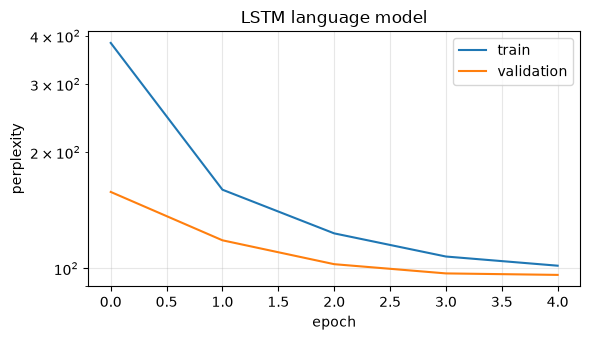

In [9]:
plt.figure(figsize=(6, 3.5))
plt.plot([math.exp(v) for v in hist["train"]], label="train")
plt.plot([math.exp(v) for v in hist["val"]],   label="validation")
plt.xlabel("epoch"); plt.ylabel("perplexity"); plt.yscale("log"); plt.legend(); plt.grid(alpha=.3)
plt.title(f"{CFG['MODEL_TYPE'].upper()} language model"); plt.tight_layout(); plt.show()

## 5. Evaluation

Besides perplexity, the metric that matters for a keyboard is **top-k next-word accuracy**: *is the word the user actually typed among the k suggestions?*
We only score positions where the true next token is a real word, and only rank real words (same filtering the keyboard applies).

In [10]:
@torch.no_grad()
def evaluate_topk(model, loader, ks=(1, 3, 5)):
    model.eval()
    hits, n = {k: 0 for k in ks}, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x).masked_fill(~is_word, float("-inf"))
        valid = is_word[y]
        top = logits.topk(max(ks), dim=-1).indices
        match = top == y.unsqueeze(-1)
        for k in ks:
            hits[k] += match[..., :k].any(-1)[valid].sum().item()
        n += valid.sum().item()
    return {f"top-{k}": hits[k] / n for k in ks}

test_loss = run_epoch(model, test_loader)
print(f"test perplexity: {math.exp(test_loss):.1f}")
for k, v in evaluate_topk(model, test_loader).items():
    print(f"{k} accuracy: {v:.1%}")

test perplexity: 90.5
top-1 accuracy: 21.7%
top-3 accuracy: 33.7%
top-5 accuracy: 39.2%


## 6. The keyboard engine

`PredictiveKeyboard` wraps a trained model and exposes three levels of functionality:

* `next_words(text, k)`: the *k* most likely next single words. If the text ends mid-word (`"the presid"`), results are restricted to words starting with that fragment (autocomplete).
* `complete_phrases(text, n_words, k)`: **beam search** for the *k* most probable multi-word continuations.
* `suggest(text, k, max_words)`: what a keyboard shows: the top-*k* next words, each greedily **extended to 2–3 words only while the model is confident** (conditional probability ≥ `extend_threshold`). That gives variable-length 1–3 word suggestions.

Special tokens and punctuation are never suggested.

In [11]:
class PredictiveKeyboard:
    def __init__(self, model, vocab, seq_len, device, temperature=1.0):
        self.model = model.eval()
        self.vocab, self.seq_len, self.device, self.temperature = vocab, seq_len, device, temperature
        self.word_mask = torch.tensor([bool(WORD_RE.match(w)) for w in vocab.itos], device=device)
        self._prefix_cache = {}

    # ---- text handling -------------------------------------------------
    def _parse(self, text):
        """Return (context_tokens, partial_word_or_None)."""
        tokens = tokenize_text(text)
        partial = None
        if text and (text[-1].isalpha() or text[-1] == "'") and tokens and WORD_RE.match(tokens[-1]):
            partial = tokens.pop()                           # user is still typing this word
        return tokens, partial

    def _allowed(self, partial):
        if not partial:
            return self.word_mask
        if partial not in self._prefix_cache:
            starts = torch.tensor([w.startswith(partial) for w in self.vocab.itos], device=self.device)
            self._prefix_cache[partial] = starts & self.word_mask
        return self._prefix_cache[partial]

    def _ctx_ids(self, tokens):
        return self.vocab.encode(tokens[-self.seq_len:]) or [EOS]   # empty context = start of text

    @torch.no_grad()
    def _logprobs(self, contexts, partial=None):
        """contexts: list of equal-length token lists -> (B, V) log-probabilities over allowed words."""
        x = torch.tensor([self._ctx_ids(c) for c in contexts], device=self.device)
        logits = self.model(x)[:, -1, :].float()
        logits = logits.masked_fill(~self._allowed(partial), float("-inf"))
        return F.log_softmax(logits / self.temperature, dim=-1)

    def _top(self, tokens, k, partial=None):
        allowed = int(self._allowed(partial).sum())
        k = min(k, allowed)
        if k == 0:
            return []
        lp = self._logprobs([tokens], partial)[0]
        v, i = lp.topk(k)
        return [(self.vocab.itos[j], math.exp(s)) for s, j in zip(v.tolist(), i.tolist())]

    # ---- public API ----------------------------------------------------
    def next_words(self, text, k=3):
        tokens, partial = self._parse(text)
        return self._top(tokens, k, partial)

    def complete_phrases(self, text, n_words=3, k=3, beam=10):
        """Beam search -> k most probable n_words-long continuations: [(phrase, probability)]."""
        tokens, partial = self._parse(text)
        first = self._top(tokens, beam, partial)
        if not first:
            return []
        beams = [(tokens + [w], math.log(p)) for w, p in first]
        for _ in range(n_words - 1):
            lps = self._logprobs([b[0] for b in beams])
            cand = []
            for (ctx, score), row in zip(beams, lps):
                v, i = row.topk(min(beam, int(self.word_mask.sum())))
                cand += [(ctx + [self.vocab.itos[j]], score + s) for s, j in zip(v.tolist(), i.tolist())]
            beams = sorted(cand, key=lambda c: -c[1])[:beam]
        n = len(tokens)
        return [(" ".join(c[0][n:]), math.exp(c[1])) for c in beams[:k]]

    def suggest(self, text, k=3, max_words=3, extend_threshold=0.5):
        """Keyboard suggestions: [(1-3 word string, probability of its first word)]."""
        tokens, partial = self._parse(text)
        out = []
        for word, p in self._top(tokens, k, partial):
            phrase, ctx = [word], tokens + [word]
            while len(phrase) < max_words:
                (nxt, pn), = self._top(ctx, 1)
                if pn < extend_threshold:
                    break
                phrase.append(nxt); ctx.append(nxt)
            out.append((" ".join(phrase), p))
        return out


def apply_suggestion(text, suggestion):
    """Insert a chosen suggestion, replacing the half-typed word if there is one."""
    if text and not text[-1].isspace():
        text = re.sub(r"[A-Za-z']+$", "", text)
    return text + suggestion + " "


kb = PredictiveKeyboard(model, vocab, CFG["SEQ_LEN"], device)

In [12]:
tests = ["the", "in the year", "he said that the", "the president of the", "she was born in", "the unit", "it was one of the most"]
for t in tests:
    print(f"\n▶ {t!r}")
    print("   next words :", ", ".join(f"{w} ({p:.0%})" for w, p in kb.next_words(t, 3)))
    print("   keyboard   :", " | ".join(s for s, _ in kb.suggest(t, k=3)))
    print("   phrases    :", " | ".join(f"{s} ({p:.1%})" for s, p in kb.complete_phrases(t, n_words=3, k=3)))


▶ 'the'
   next words : the (92%), there (3%), they (2%)
   keyboard   : the | there | they
   phrases    : the united states (0.7%) | the new york (0.2%) | the first time (0.2%)

▶ 'in the year'
   next words : year (85%), years (13%), year's (2%)
   keyboard   : year | years | year's
   phrases    : year of the (3.9%) | years of the (2.4%) | year after the (0.9%)

▶ 'he said that the'
   next words : the (79%), they (11%), there (7%)
   keyboard   : the | they | there
   phrases    : the episode was (1.3%) | the song was (1.0%) | the film was (0.6%)

▶ 'the president of the'
   next words : the (98%), their (1%), these (0%)
   keyboard   : the | their | these
   phrases    : the united states (1.9%) | the university of (1.1%) | the church of (0.6%)

▶ 'she was born in'
   next words : in (99%), into (1%), inside (0%)
   keyboard   : in | into | inside the
   phrases    : in the united (3.0%) | in the early (1.2%) | in the late (1.1%)

▶ 'the unit'
   next words : united (94%), unit 

In [13]:
# Inference latency: a keyboard must feel instant (< ~50 ms).
prefixes = ["the president of the", "in the year", "he said that the", "she was born in"] * 25
kb.suggest(prefixes[0])                                   # warm-up
if device.type == "cuda": torch.cuda.synchronize()
t0 = time.perf_counter()
for p in prefixes:
    kb.suggest(p, k=3, max_words=3)
if device.type == "cuda": torch.cuda.synchronize()
print(f"average suggest() latency: {(time.perf_counter() - t0) / len(prefixes) * 1000:.1f} ms on {device}")

average suggest() latency: 26.9 ms on cpu


## 7. Interactive demo

Type in the box; three suggestion buttons update on every keystroke. Click one to insert it (a half-typed word is replaced by the completion).

In [14]:
try:
    import ipywidgets as widgets
    from IPython.display import display

    box = widgets.Text(placeholder="Start typing, e.g. 'the president of the'",
                       layout=widgets.Layout(width="90%"), continuous_update=True)
    buttons = [widgets.Button(description="—", disabled=True, layout=widgets.Layout(width="30%", height="40px"))
               for _ in range(3)]
    info = widgets.HTML()

    def refresh(change=None):
        t0 = time.perf_counter()
        sugg = kb.suggest(box.value, k=3, max_words=3)
        ms = (time.perf_counter() - t0) * 1000
        for i, b in enumerate(buttons):
            if i < len(sugg):
                b.description, b.disabled = sugg[i][0], False
                b.tooltip = f"p(first word) = {sugg[i][1]:.1%}"
            else:
                b.description, b.disabled, b.tooltip = "—", True, ""
        info.value = f"<small>{ms:.0f} ms</small>"

    def on_click(b):
        box.value = apply_suggestion(box.value, b.description)

    for b in buttons:
        b.on_click(on_click)
    box.observe(refresh, names="value")
    refresh()
    display(box, widgets.HBox(buttons), info)
except ImportError:
    print("ipywidgets not installed; use kb.suggest('your text') instead.")

Text(value='', layout=Layout(width='90%'), placeholder="Start typing, e.g. 'the president of the'")

HTML(value='<small>107 ms</small>')

## 8. Save and reload the model

The checkpoint stores weights, config and vocabulary, so the keyboard can be reloaded without retraining.

In [15]:
def save_checkpoint(model, model_type, path=None):
    Path(CFG["CKPT_DIR"]).mkdir(exist_ok=True)
    path = path or f"{CFG['CKPT_DIR']}/keyboard_{model_type}.pt"
    torch.save(dict(state=model.state_dict(), model_type=model_type, cfg=CFG, itos=vocab.itos), path)
    print("saved ->", path, f"({Path(path).stat().st_size / 1e6:.1f} MB)")
    return path

def load_keyboard(path):
    ck = torch.load(path, map_location=device)
    v = Vocab(itos=ck["itos"])
    CFG.update(ck["cfg"])
    global V
    V = len(v)
    m = build_model(ck["model_type"])
    m.load_state_dict(ck["state"])
    return PredictiveKeyboard(m, v, CFG["SEQ_LEN"], device)

ckpt = save_checkpoint(model, CFG["MODEL_TYPE"])
kb2 = load_keyboard(ckpt)
print(kb2.suggest("the president of the"))

saved -> checkpoints/keyboard_lstm.pt (26.5 MB)
[('the', 0.980466314084285), ('their', 0.01234372374407463), ('these', 0.0028672454150732705)]
